# 2. Injection

The benchmark makes an episode by multiplying a real light curve by a transit model.
The model used to add the transit is [batman](https://lkreidberg.github.io/batman/docs/html/index.html) , with the geometry from the star's radius and surface gravity.
This notebook builds one transit from its parameters and shows how each parameter affects the shape

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

sys.path.insert(0, str(Path("..").resolve()))
sys.path.insert(0, str(Path("../tests").resolve()))
plt.rcParams["figure.figsize"] = (11, 3.5)
plt.rcParams["figure.dpi"] = 110

EPISODES = Path("../data/episodes/s98_v2")


def load_episode(episode_id="ep_0001"):
    """Return (time, flux, truth) for one real episode, or a synthetic one if the set is absent."""
    if EPISODES.exists():
        from stargazer.episodes import EpisodeSet

        episode_set = EpisodeSet(EPISODES)
        time, flux, _ = episode_set.load(episode_id)
        return time, flux, episode_set.truth[episode_id]
    from conftest import synthetic_lc

    from stargazer.inject import inject, make_truth

    time, flux, _ = synthetic_lc(days=57.0)
    time = time - time.min()
    star = {"teff": 5500.0, "logg": 4.45, "radius_rsun": 0.95, "tmag": 10.0, "mass_msun": 0.95}
    truth = make_truth(period=0.7764, t0=0.1453, depth=0.0016, b=0.3, star=star)
    transit = {"period": truth.period, "t0": truth.t0, "duration": truth.duration, "depth": truth.depth}
    record = {"kind": "transit", "n_transits": 73, "snr": 60.0, "transit": transit}
    return time, inject(time, flux, truth), record


time, flux, truth = load_episode()
epoch = float(np.round(np.median(time), 1))  # a time with data: the episode has gaps
print(f"{len(time)} points over {time.max() - time.min():.1f} days; truth kind {truth['kind']}")
print(f"epoch for the examples: {epoch} d")

26521 points over 57.4 days; truth kind transit
epoch for the examples: 28.8 d


## From depth and period to a shape

`make_truth` takes 
- a period, 
- an epoch, 
- a depth and an impact parameter, 
- and a host star. 

It derives the radius ratio from the depth, the scaled semi-major axis from
Kepler's third law, the inclination from the impact parameter, the limb darkening
from the star's temperature, and the duration from all of them. 
Then return as a record truth for the particular star

In [2]:
from stargazer.inject import make_truth, transit_model

star = {"teff": 5500.0, "logg": 4.45, "radius_rsun": 0.95, "tmag": 10.0, "mass_msun": 0.95}
example = make_truth(period=5.0, t0=epoch, depth=0.005, b=0.3, star=star)
for name, value in vars(example).items():
    print(f"{name:10s} {value:.5g}")

period     5
t0         28.8
rp_rs      0.070711
a_rs       12.632
inc_deg    88.639
b          0.3
u1         0.4
u2         0.25
duration   0.12967
depth      0.005


## The shape of one transit

The plot shows the model around one transit for three impact parameters. 
- At b = 0 the planet crosses the centre of the disc: a long, flat-bottomed dip. 
- At b = 0.9 it crosses near the limb: shorter and rounder.
- At b above 1 minus the radius ratio the planet never lies fully on the disc: a V shape with no flat bottom, which resembles
shape of a grazing eclipsing binary too.

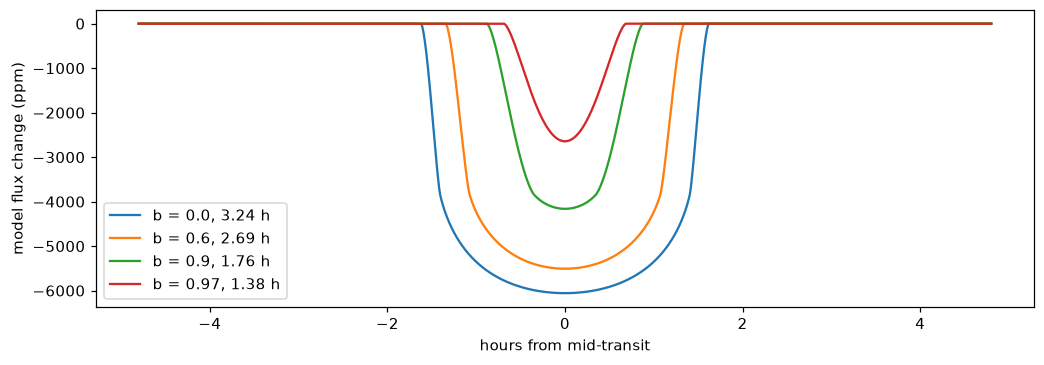

In [3]:
grid = np.linspace(epoch - 0.2, epoch + 0.2, 2000)
fig, axis = plt.subplots()
for b in (0.0, 0.6, 0.9, 0.97):
    model = make_truth(period=5.0, t0=epoch, depth=0.005, b=b, star=star)
    change_ppm = (transit_model(grid, model) - 1) * 1e6
    axis.plot((grid - epoch) * 24, change_ppm, label=f"b = {b}, {model.duration * 24:.2f} h")
axis.set_xlabel("hours from mid-transit")
axis.set_ylabel("model flux change (ppm)")
axis.legend()
plt.show()

## Injection into noise

`inject` multiplies the flux by the model. The plot shows the same transit in the
real noise of the loaded episode.

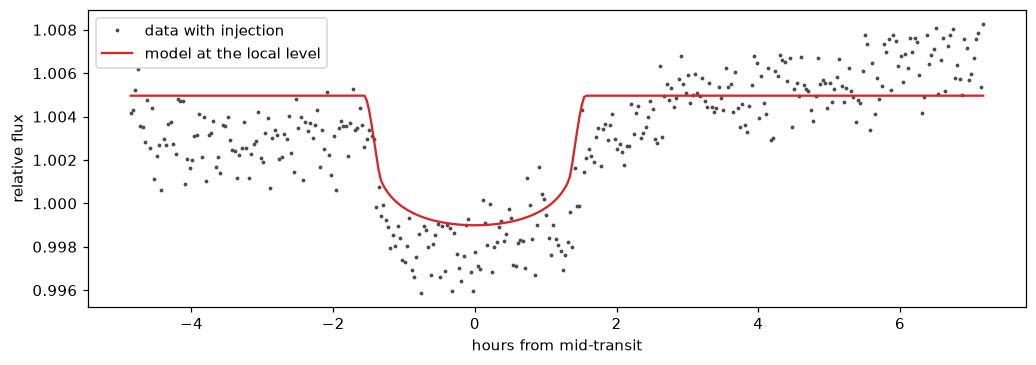

In [4]:
from stargazer.inject import inject

injected = inject(time, flux, example)
window = np.abs(time - epoch) < 0.3
level = np.nanmedian(
    injected[window & (np.abs(time - epoch) > example.duration)]
)  # local out-of-transit flux
fig, axis = plt.subplots()
axis.plot((time[window] - epoch) * 24, injected[window], ".", ms=3, color="0.3", label="data with injection")
axis.plot(
    (time[window] - epoch) * 24,
    level * transit_model(time[window], example),
    color="tab:red",
    label="model at the local level",
)
axis.set_xlabel("hours from mid-transit")
axis.set_ylabel("relative flux")
axis.legend()
plt.show()